# TP Final · Opción B · 02 · Experimentos con MLflow

Se entrenan y comparan varios modelos de **regresión** para predecir `Delivery_Time` (minutos), sobre la tabla `delivery_features` que dejó el notebook 01.

**Estrategia de evaluación (igual para todos los modelos):**
- Partición **temporal**: `train` hasta el 29/03/2022 y `test` los pedidos posteriores.
- Mismas variables y misma semilla (`random_state=42`) en todos los runs.
- Métricas: **RMSE** (principal, penaliza más los errores grandes), **MAE** (error promedio en minutos) y **R²**, en train y en test. Comparar train con test permite detectar sobreajuste.
- Línea de base: predecir siempre el promedio de `train`. Un modelo que no la supera no aprendió nada.

Cada configuración queda como un **run** de MLflow con sus parámetros, métricas y artefactos (gráficos, importancia de variables y el modelo con su firma).

In [0]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from mlflow.models import infer_signature

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TABLA = "workspace.tp_final_belu.delivery_features"
SEED = 42

## 1. Datos y experimento

In [0]:
df = spark.table(TABLA).toPandas()
data_version = spark.sql(f"DESCRIBE HISTORY {TABLA}").first()["version"]

NUM = ["Agent_Age", "Agent_Rating", "distancia_km", "coords_invalidas", "hora_pedido", "dia_semana", "demora_recogida_min"]
CAT = ["Weather", "Traffic", "Vehicle", "Area", "Category"]
FEATURES = NUM + CAT
TARGET = "Delivery_Time"

for c in CAT:   # los nulos de Spark llegan como None: se pasan a NaN para que el imputador los detecte
    df[c] = df[c].astype(object).where(df[c].notna(), np.nan)

train = df[df["split"] == "train"]
test = df[df["split"] == "test"]
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"train: {len(train):,} filas · test: {len(test):,} filas · versión de la tabla: {data_version}")
print(f"Tiempo medio de entrega: train {y_train.mean():.1f} min · test {y_test.mean():.1f} min")

usuario = spark.sql("SELECT current_user()").first()[0]
experimento = mlflow.set_experiment(f"/Users/{usuario}/tp_final_delivery")
print("Experimento:", experimento.name)

{"ts": "2026-10-29 16:43:48.266", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chlub3RlYm9va3MvNDA4OTU4MzM1NTIwNTU0EAEgATIkMDFhMTg4OGItYTQzMy03ZmMyLWEzZmYtMjRhNzU1ZmRjOWI3OiQ4MjM1NzBmNS1lZGIwLTMxODUtYWY0ZS0xOWIwZThjMzY4YjhKDAi3743XBhDAmbulAVABWAFgAWi+j/D548SjDYgBAA==.", "context": {}}
{"ts": "2026-10-29 16:43:48.266", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chlub3RlYm9va3MvNDA4OTU4MzM1NTIwNTU0EAEgATIkMDFhMTg4OGItYTQzMy03ZmMyLWEzZmYtMjRhNzU1ZmRjOWI3OiQ4MjM1NzBmNS1lZGIwLTMxODUtYWY0ZS0xOWIwZThjMzY4YjhKDAi3743XBhDAmbulAVABWAFgAWi+j/D548SjDYgBAA==.", "context": {}}
{"ts": "2026-10-29 16:43:48.266", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chlub3RlYm9va3MvNDA4OTU4MzM1NTIwNTU0EAEgATIkMDFhMTg4OGItYTQzMy03ZmMyLWEzZmYtMjRhNzU1ZmRjOWI3OiQ4MjM1NzBmNS1lZGIwLTMxODUtYWY0ZS0xOWIwZThj

train: 35,620 filas · test: 8,119 filas · versión de la tabla: 0
Tiempo medio de entrega: train 125.1 min · test 124.1 min


2026/10/29 16:43:54 INFO mlflow.tracking.fluent: Experiment with name '/Users/maripena@itba.edu.ar/tp_final_delivery' does not exist. Creating a new experiment.


Experimento: /Users/maripena@itba.edu.ar/tp_final_delivery


## 2. Preprocesamiento y función de entrenamiento

El preprocesamiento va **dentro del Pipeline** de cada modelo, así se ajusta sólo con `train` y no se filtra información del test:
- Variables numéricas: imputación con la mediana y escalado.
- Variables categóricas: imputación con la categoría más frecuente y codificación *one-hot*.

`train_and_log` entrena un modelo, calcula las métricas y registra todo en MLflow.

In [0]:
def preprocesador():
    numericas = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    categoricas = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                            ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", numericas, NUM), ("cat", categoricas, CAT)])

def metricas(y_real, y_pred, prefijo):
    return {f"{prefijo}_rmse": float(np.sqrt(mean_squared_error(y_real, y_pred))),
            f"{prefijo}_mae": float(mean_absolute_error(y_real, y_pred)),
            f"{prefijo}_r2": float(r2_score(y_real, y_pred))}

def train_and_log(nombre, modelo, params):
    pipeline = Pipeline([("prep", preprocesador()), ("modelo", modelo)])
    with mlflow.start_run(run_name=nombre, tags={"notebook": "02", "problema": "delivery_time"}) as run:
        mlflow.log_params({**params, "modelo": type(modelo).__name__, "features": len(FEATURES),
                           "split": "temporal 2022-03-29", "seed": SEED,
                           "tabla": TABLA, "data_version": data_version})
        pipeline.fit(X_train, y_train)
        pred_train, pred_test = pipeline.predict(X_train), pipeline.predict(X_test)
        m = {**metricas(y_train, pred_train, "train"), **metricas(y_test, pred_test, "test")}
        mlflow.log_metrics(m)

        # Artefactos: real vs. predicho, errores e importancia de variables (por permutación, sobre test)
        muestra = np.random.default_rng(SEED).choice(len(y_test), size=min(2000, len(y_test)), replace=False)
        fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
        ejes[0].scatter(y_test.to_numpy()[muestra], pred_test[muestra], s=6, alpha=0.4, color="#2563eb")
        ejes[0].plot([10, 270], [10, 270], color="black", ls="--")
        ejes[0].set_xlabel("Tiempo real (min)"); ejes[0].set_ylabel("Tiempo predicho (min)"); ejes[0].set_title("Real vs. predicho (test)")
        ejes[1].hist(y_test.to_numpy() - pred_test, bins=40, color="#f59e0b")
        ejes[1].set_xlabel("Error = real - predicho (min)"); ejes[1].set_title("Distribución del error (test)")
        fig.suptitle(nombre); fig.tight_layout()
        mlflow.log_figure(fig, "real_vs_predicho.png")
        plt.close(fig)

        idx = np.random.default_rng(SEED).choice(len(X_test), size=min(3000, len(X_test)), replace=False)
        imp = permutation_importance(pipeline, X_test.iloc[idx], y_test.iloc[idx], n_repeats=5, random_state=SEED,
                                     scoring="neg_root_mean_squared_error")
        importancia = (pd.DataFrame({"variable": FEATURES, "importancia_rmse": imp.importances_mean})
                       .sort_values("importancia_rmse", ascending=False))
        mlflow.log_text(importancia.round(4).to_csv(index=False), "importancia_variables.csv")

        firma = infer_signature(X_test, pred_test)
        try:
            mlflow.sklearn.log_model(pipeline, name="model", signature=firma, serialization_format="cloudpickle")
        except TypeError:   # versiones anteriores de MLflow usan artifact_path
            mlflow.sklearn.log_model(pipeline, artifact_path="model", signature=firma, serialization_format="cloudpickle")
    print(f"{nombre:<28} test RMSE {m['test_rmse']:.2f} · MAE {m['test_mae']:.2f} · R² {m['test_r2']:.3f}"
          f"  | train RMSE {m['train_rmse']:.2f}")
    return {"run": nombre, "run_id": run.info.run_id, **m}

## 3. Los experimentos

Seis configuraciones comparables:
1. **Línea de base:** predice siempre el promedio de `train`.
2. **Ridge:** regresión lineal con regularización (un modelo simple e interpretable).
3. **Random forest (profundidad 8)** y 4. **Random forest (profundidad 16)**: miden el efecto de la complejidad del árbol.
5. **Gradient boosting (lr 0,1)** y 6. **Gradient boosting (lr 0,05, más iteraciones)**: dos configuraciones del boosting.

In [0]:
resultados = []

resultados.append(train_and_log("0_linea_base_media", DummyRegressor(strategy="mean"), {"estrategia": "media"}))

resultados.append(train_and_log("1_ridge", Ridge(alpha=1.0), {"alpha": 1.0}))

for profundidad in (8, 16):
    params = {"n_estimators": 150, "max_depth": profundidad, "min_samples_leaf": 5}
    resultados.append(train_and_log(f"2_random_forest_prof{profundidad}",
                                    RandomForestRegressor(random_state=SEED, n_jobs=-1, **params), params))

for lr, iters in ((0.1, 200), (0.05, 400)):
    params = {"learning_rate": lr, "max_iter": iters, "max_depth": 6}
    resultados.append(train_and_log(f"3_gradient_boosting_lr{lr}",
                                    HistGradientBoostingRegressor(random_state=SEED, **params), params))

/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
🔗 View Logged Model at: https://dbc-e781d68e-abac.cloud.databricks.com/ml/experiments/408958335520555/models/m-74406880aab3448287359348e527890f?o=7474644315277246


0_linea_base_media           test RMSE 51.58 · MAE 40.96 · R² -0.000  | train RMSE 51.99


/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
🔗 View Logged Model at: https://dbc-e781d68e-abac.cloud.databricks.com/ml/experiments/408958335520555/models/m-8a1be89c8f3441938c4def44237da6d6?o=7474644315277246


1_ridge                      test RMSE 32.24 · MAE 25.35 · R² 0.609  | train RMSE 32.48


/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
🔗 View Logged Model at: https://dbc-e781d68e-abac.cloud.databricks.com/ml/experiments/408958335520555/models/m-b601a4dafd2a4d428722d47a0a6fa405?o=7474644315277246


...

2_random_forest_prof16       test RMSE 22.83 · MAE 17.63 · R² 0.804  | train RMSE 18.26


/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
🔗 View Logged Model at: https://dbc-e781d68e-abac.cloud.databricks.com/ml/experiments/408958335520555/models/m-8333ad0a9c0b4e4dadad953cd8a5eb48?o=7474644315277246


3_gradient_boosting_lr0.1    test RMSE 22.90 · MAE 17.80 · R² 0.803  | train RMSE 22.11


/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
🔗 View Logged Model at: https://dbc-e781d68e-abac.cloud.databricks.com/ml/experiments/408958335520555/models/m-343ae6129bb742c0b913506a9be32161?o=7474644315277246


3_gradient_boosting_lr0.05   test RMSE 22.89 · MAE 17.78 · R² 0.803  | train RMSE 22.38


## 4. Comparación de los runs

Los runs se consultan desde MLflow (`search_runs`) y se ordenan por **RMSE de test**, la métrica de selección. La diferencia entre el RMSE de train y el de test indica si hay sobreajuste.

In [0]:
runs = mlflow.search_runs(experiment_ids=[experimento.experiment_id],
                          filter_string="tags.notebook = '02'", order_by=["metrics.test_rmse ASC"])
tabla = runs[["tags.mlflow.runName", "metrics.train_rmse", "metrics.test_rmse", "metrics.test_mae", "metrics.test_r2"]].copy()
tabla.columns = ["run", "train_rmse", "test_rmse", "test_mae", "test_r2"]
tabla["brecha_train_test"] = tabla["test_rmse"] - tabla["train_rmse"]
tabla = tabla.round(3).reset_index(drop=True)
tabla

,run,train_rmse,test_rmse,test_mae,test_r2,brecha_train_test
0,2_random_forest_prof16,18.263,22.832,17.628,0.804,4.570
1,3_gradient_boosting_lr0.05,22.376,22.887,17.784,0.803,0.511
2,3_gradient_boosting_lr0.1,22.108,22.904,17.804,0.803,0.795
3,2_random_forest_prof8,24.266,24.352,18.759,0.777,0.087
4,1_ridge,32.481,32.240,25.354,0.609,-0.241
5,0_linea_base_media,51.992,51.579,40.962,-0.000,-0.413


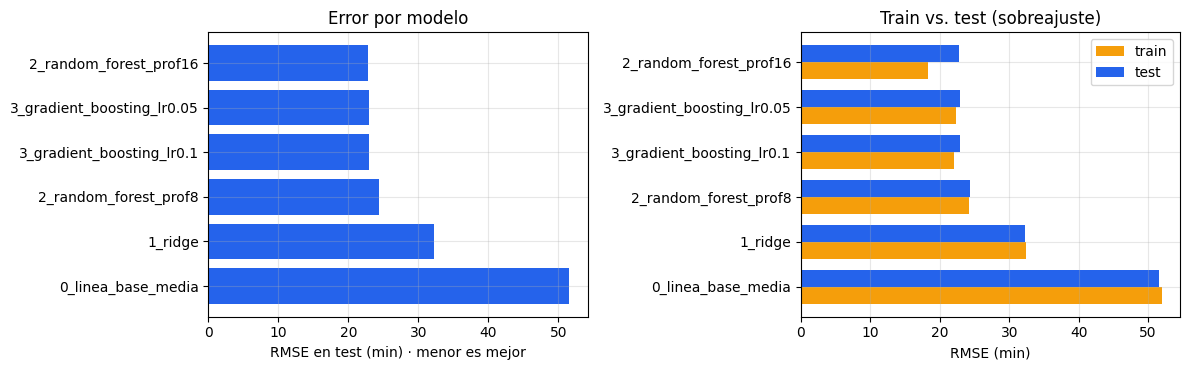

In [0]:
orden = tabla.sort_values("test_rmse", ascending=False)
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
ejes[0].barh(orden["run"], orden["test_rmse"], color="#2563eb")
ejes[0].set_xlabel("RMSE en test (min) · menor es mejor"); ejes[0].set_title("Error por modelo")
ancho = 0.38
pos = np.arange(len(orden))
ejes[1].barh(pos - ancho / 2, orden["train_rmse"], height=ancho, color="#f59e0b", label="train")
ejes[1].barh(pos + ancho / 2, orden["test_rmse"], height=ancho, color="#2563eb", label="test")
ejes[1].set_yticks(pos); ejes[1].set_yticklabels(orden["run"])
ejes[1].set_xlabel("RMSE (min)"); ejes[1].set_title("Train vs. test (sobreajuste)"); ejes[1].legend()
for ax in ejes: ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 5. Mejor modelo: importancia de variables y errores

Se toma el run con menor RMSE de test y se leen sus artefactos.

In [0]:
mejor = runs.iloc[0]
print(f"Mejor run: {mejor['tags.mlflow.runName']} · test RMSE {mejor['metrics.test_rmse']:.2f} min · "
      f"MAE {mejor['metrics.test_mae']:.2f} min · R² {mejor['metrics.test_r2']:.3f}")
base = runs[runs["tags.mlflow.runName"] == "0_linea_base_media"].iloc[0]
print(f"Línea de base (promedio): RMSE {base['metrics.test_rmse']:.2f} min · MAE {base['metrics.test_mae']:.2f} min")
print(f"Mejora del RMSE respecto de la línea de base: {1 - mejor['metrics.test_rmse'] / base['metrics.test_rmse']:.1%}")

imp = pd.read_csv(mlflow.artifacts.download_artifacts(run_id=mejor["run_id"], artifact_path="importancia_variables.csv"))
display(imp)

Mejor run: 2_random_forest_prof16 · test RMSE 22.83 min · MAE 17.63 min · R² 0.804
Línea de base (promedio): RMSE 51.58 min · MAE 40.96 min
Mejora del RMSE respecto de la línea de base: 55.7%


variable,importancia_rmse
Category,21.5988
Weather,14.5547
Traffic,13.6275
Agent_Rating,12.3254
distancia_km,12.1816
Agent_Age,9.2865
Vehicle,3.1282
Area,0.4549
coords_invalidas,0.209
hora_pedido,0.1564


In [0]:
cargado = mlflow.sklearn.load_model(f"runs:/{mejor['run_id']}/model")
test_pred = test.assign(prediccion=cargado.predict(X_test))
test_pred["error_abs"] = (test_pred[TARGET] - test_pred["prediccion"]).abs()
for col in ["Traffic", "Weather", "Area"]:
    print(f"\nError absoluto medio por {col} (min):")
    print(test_pred.groupby(col, dropna=False)["error_abs"].mean().round(1).sort_values().to_string())
print("\nSin distancia (coordenadas inválidas) vs. con distancia:")
print(test_pred.groupby("coords_invalidas")["error_abs"].agg(filas="count", mae="mean").round(1))


Error absoluto medio por Traffic (min):
Traffic
Low       14.7
Medium    18.2
High      18.7
Jam       20.1
NaN       23.5

Error absoluto medio por Weather (min):
Weather
Fog           16.5
Cloudy        17.0
Stormy        17.5
Sunny         17.5
Sandstorms    18.5
Windy         18.7
NaN           23.5

Error absoluto medio por Area (min):
Area
Metropolitan    17.6
Urban           17.6
Other           18.0
Semi-Urban      25.2

Sin distancia (coordenadas inválidas) vs. con distancia:
                  filas   mae
coords_invalidas             
0                  7609  17.3
1                   510  22.6


## 6. Tabla para el README

Se imprime en formato Markdown para pegarla en el informe.

In [0]:
def a_markdown(d):
    filas = ["| " + " | ".join(d.columns) + " |", "|" + "---|" * len(d.columns)]
    filas += ["| " + " | ".join(str(v) for v in fila) + " |" for fila in d.to_numpy()]
    return "\n".join(filas)
print(a_markdown(tabla))

| run | train_rmse | test_rmse | test_mae | test_r2 | brecha_train_test |
|---|---|---|---|---|---|
| 2_random_forest_prof16 | 18.263 | 22.832 | 17.628 | 0.804 | 4.57 |
| 3_gradient_boosting_lr0.05 | 22.376 | 22.887 | 17.784 | 0.803 | 0.511 |
| 3_gradient_boosting_lr0.1 | 22.108 | 22.904 | 17.804 | 0.803 | 0.795 |
| 2_random_forest_prof8 | 24.266 | 24.352 | 18.759 | 0.777 | 0.087 |
| 1_ridge | 32.481 | 32.24 | 25.354 | 0.609 | -0.241 |
| 0_linea_base_media | 51.992 | 51.579 | 40.962 | -0.0 | -0.413 |


## Cierre

- **Modelo elegido** y por qué (RMSE y MAE de test, comparados con la línea de base y con el resto).
- **Sobreajuste:** mirar la brecha entre el RMSE de train y el de test de cada run.
- **Variables más importantes** y si tienen sentido para el negocio.
- **Limitaciones:** el período es corto (unas 8 semanas), hay pedidos sin distancia por coordenadas inválidas, no se conoce el tráfico real minuto a minuto y el tiempo de entrega tiene un componente aleatorio que un modelo no explica.